In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from eval.data import load_and_split
from medal.model import AutoEncoder
from medal.normalizer import GlobalEmbeddingNormalizer
import torch
import matplotlib.ticker as ticker
from pathlib import Path
from sklearn.model_selection import train_test_split
from utils import compute_param_choice, build_figure, build_distortion_figure
# Set MEDAL_DATA_DIR to the parent directory of your data (drd_data/ and MEDAL/ live here)
import os
PATH_PREFIX = os.environ.get('MEDAL_DATA_DIR', os.path.expanduser('~'))
%load_ext autoreload
%autoreload 2

/home/bnc2119/.conda/envs/medal/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-05-01 16:38:19,566	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-05-01 16:38:19,980	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
# loading AE
def load_trained_ae(ckpt_path, input_dim, hidden_dims, latent_dim=2, batchnorm=False):
    import sys, os
    old_stdout = sys.stdout
    sys.stdout = open(os.devnull, "w")
    model = AutoEncoder(
        input_dim=input_dim,
        latent_dim=latent_dim,
        hidden_dims=hidden_dims,
        activation=torch.nn.SELU,          
        bottleneck_activation=None,
        use_batchnorm = batchnorm
    )
    sys.stdout = old_stdout

    sd = torch.load(ckpt_path, map_location="cpu")

    if isinstance(sd, dict) and "model" in sd and isinstance(sd["model"], dict):
        sd = sd["model"]
    elif isinstance(sd, dict) and "state_dict" in sd and isinstance(sd["state_dict"], dict):
        sd = sd["state_dict"]

    sd = {k.replace("module.", ""): v for k, v in sd.items()}

    missing, unexpected = model.load_state_dict(sd, strict=False)
    print(f"loaded params: {len(sd)} | missing={len(missing)} | unexpected={len(unexpected)}")
    if missing or unexpected:
        print("⚠️ Check architecture/keys. Example missing:", missing[:3], "unexpected:", unexpected[:3])

    model.eval()
    return model

def split_scdeed_labels(df, best_param):
    result = []
    for l in ["dubious", "trustworthy", "intermediate"]:
        vec = df.loc[best_param, f"{l}_cells"]
        ls_indices = np.array(vec.split(',')).astype(int)
        result.extend(list(zip([l]* len(ls_indices), ls_indices)))
    return pd.DataFrame(result, columns = ['label', 'index']).set_index('index').sort_index()

In [3]:
X_og, X_test, y_og, y_test = load_and_split("hydra", test_size=0.2, seed=0, labels=True)
X, X_val, y, y_val = train_test_split(X_og, y_og, test_size=0.2, random_state=0)

hydra_palette = color_map = {
    "enEp_tentacle": "#1e3a8a",
    "enEp_stem_cell": "#1d4ed8",
    "enEp_foot": "#2563eb",
    "enEp_head": "#3b82f6",
    "enEp-nb(pd)": "#60a5fa",
    "enEp-nem(pd)": "#93c5fd",
    "enEp_tent-nem(pd)": "#bfdbfe",
    "ecEp-nb(pd)": "#134e4a",
    "ecEp_battery_cell2(mp)": "#0f766e",
    "ecEp_stem_cell": "#0d9488",
    "ecEp_head": "#14b8a6",
    "ecEp-nem(id)": "#2dd4bf",
    "ecEp_basal_disk": "#5eead4",
    "ecEp_battery_cell1(mp)": "#99f6e4",
    "i_stem_cell/progenitor": "#4a044e",
    "i_neuron/gland_cell_progenitor": "#6b21a8",
    "i_neuron_progenitor": "#7e22ce",
    "i_nb1": "#7c2d12",
    "i_nb2": "#c2410c",
    "i_nb3": "#ea580c",
    "i_nb4": "#f97316",
    "i_nb5": "#fb923c",
    "i_neuron_ec1": "#831843",
    "i_neuron_ec2": "#be185d",
    "i_neuron_ec3": "#db2777",
    "i_neuron_ec4": "#ec4899",
    "i_neuron_ec5": "#f472b6",
    "i_neuron_en1": "#3b0764",
    "i_neuron_en2": "#5b21b6",
    "i_neuron_en3": "#7c3aed",
    "i_female_germline1": "#312e81",
    "i_female_germline2_nurse": "#4338ca",
    "i_male_germline": "#818cf8",
    "i_granular_mucous_gland_cell": "#7f1d1d",
    "i_zymogen_gland_cell": "#b91c1c",
    "i_spumous_mucous_gland_cell": "#ef4444",
    "i_nematocyte": "#92400e",
    "db": "#d97706",
}

category_map = {
    "enEp_tentacle": "enEp",
    "enEp_stem_cell": "enEp",
    "enEp_foot": "enEp",
    "enEp_head": "enEp",
    "enEp-nb(pd)": "enEp",
    "enEp-nem(pd)": "enEp",
    "enEp_tent-nem(pd)": "enEp",
    "ecEp-nb(pd)": "ecEp",
    "ecEp_battery_cell2(mp)": "ecEp",
    "ecEp_stem_cell": "ecEp",
    "ecEp_head": "ecEp",
    "ecEp-nem(id)": "ecEp",
    "ecEp_basal_disk": "ecEp",
    "ecEp_battery_cell1(mp)": "ecEp",
    "i_stem_cell/progenitor": "i_progenitors",
    "i_neuron/gland_cell_progenitor": "i_progenitors",
    "i_neuron_progenitor": "i_progenitors",
    "i_nb1": "i_neuroblasts",
    "i_nb2": "i_neuroblasts",
    "i_nb3": "i_neuroblasts",
    "i_nb4": "i_neuroblasts",
    "i_nb5": "i_neuroblasts",
    "i_neuron_ec1": "i_neurons_ec",
    "i_neuron_ec2": "i_neurons_ec",
    "i_neuron_ec3": "i_neurons_ec",
    "i_neuron_ec4": "i_neurons_ec",
    "i_neuron_ec5": "i_neurons_ec",
    "i_neuron_en1": "i_neurons_en",
    "i_neuron_en2": "i_neurons_en",
    "i_neuron_en3": "i_neurons_en",
    "i_female_germline1": "i_germline",
    "i_female_germline2_nurse": "i_germline",
    "i_male_germline": "i_germline",
    "i_granular_mucous_gland_cell": "i_gland",
    "i_zymogen_gland_cell": "i_gland",
    "i_spumous_mucous_gland_cell": "i_gland",
    "i_nematocyte": "i_nematocyte",
    "db": "db",
}

In [4]:
y_og_big_categories = pd.Series(y_og).map(category_map).values
y_big_categories = pd.Series(y).map(category_map).values
y_test_big_categories = pd.Series(y_test).map(category_map).values
y_val_big_categories = pd.Series(y_val).map(category_map).values

## Hyperparameter Tuning

In [8]:
hydra_tsne_res_dict = []
for s in range(5):
    for perp in np.unique(np.logspace(np.log10(5), np.log10(5000), 10).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_tsne_{perp}_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_tsne_{perp}_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/hydra/medal_tsne2_{perp}_tc0_{s}_ckpts/final.pt",
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)

        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            hydra_tsne_res_dict.append({"perplexity": perp, "recon_loss": train_recon, "split": "Train", "seed": s})

            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            hydra_tsne_res_dict.append({"perplexity": perp, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            hydra_tsne_res_dict.append({"perplexity": perp, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {perp} seed {s} due to distillation loss {train_distill}")

# ── Compute parameter choice ────────────────────────────────────────────────────────────────────────────────
analysis, tsne_one_std_range, tsne_one_std_param_choice, unique_perplexities, vline_x = \
    compute_param_choice(hydra_tsne_res_dict, 'perplexity')

/tmp/ipykernel_44296/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded par

In [6]:
# ── Load student models & compute embeddings ─────────────────────────────────────────────
list_tsne_param = [499, 5]
student_tsne01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_tsne2_{list_tsne_param[0]}_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_tsne01, student_embed_tsne01 = student_tsne01(torch.tensor(X, dtype=torch.float32))
student_recon_val_tsne01, student_embed_val_tsne01 = student_tsne01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_tsne01, student_embed_test_tsne01 = student_tsne01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_tsne01 = np.mean((student_recon_tsne01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_tsne01 = np.mean((student_recon_val_tsne01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_tsne01 = np.mean((student_recon_test_tsne01.detach().numpy() - X_test)**2, axis=1)

student_tsne02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_tsne2_{list_tsne_param[1]}_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_tsne02, student_embed_tsne02 = student_tsne02(torch.tensor(X, dtype=torch.float32))
student_recon_val_tsne02, student_embed_val_tsne02 = student_tsne02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_tsne02, student_embed_test_tsne02 = student_tsne02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_tsne02 = np.mean((student_recon_tsne02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_tsne02 = np.mean((student_recon_val_tsne02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_tsne02 = np.mean((student_recon_test_tsne02.detach().numpy() - X_test)**2, axis=1)

# ── Figure ──────────────────────────────────────────────────────────────────────────────────────────────────────────
emb_data = {
    list_tsne_param[0]: {
        'Train': (student_embed_tsne01,      per_sample_recon_tsne01,      y),
        'Val':   (student_embed_val_tsne01,  per_sample_recon_val_tsne01,  y_val),
        'Test':  (student_embed_test_tsne01, per_sample_recon_test_tsne01, y_test),
    },
    list_tsne_param[1]: {
        'Train': (student_embed_tsne02,      per_sample_recon_tsne02,      y),
        'Val':   (student_embed_val_tsne02,  per_sample_recon_val_tsne02,  y_val),
        'Test':  (student_embed_test_tsne02, per_sample_recon_test_tsne02, y_test),
    },
}


/tmp/ipykernel_6613/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0


In [ ]:
build_figure(
    analysis, 'perplexity', unique_perplexities, tsne_one_std_range, vline_x,
    emb_data, list_tsne_param, tsne_one_std_param_choice,
    hydra_palette, 'perplexity', 'Perplexity',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'lower right', 'bbox_to_anchor': (0.5, 1)},
    xtick_fontsize=8,
)

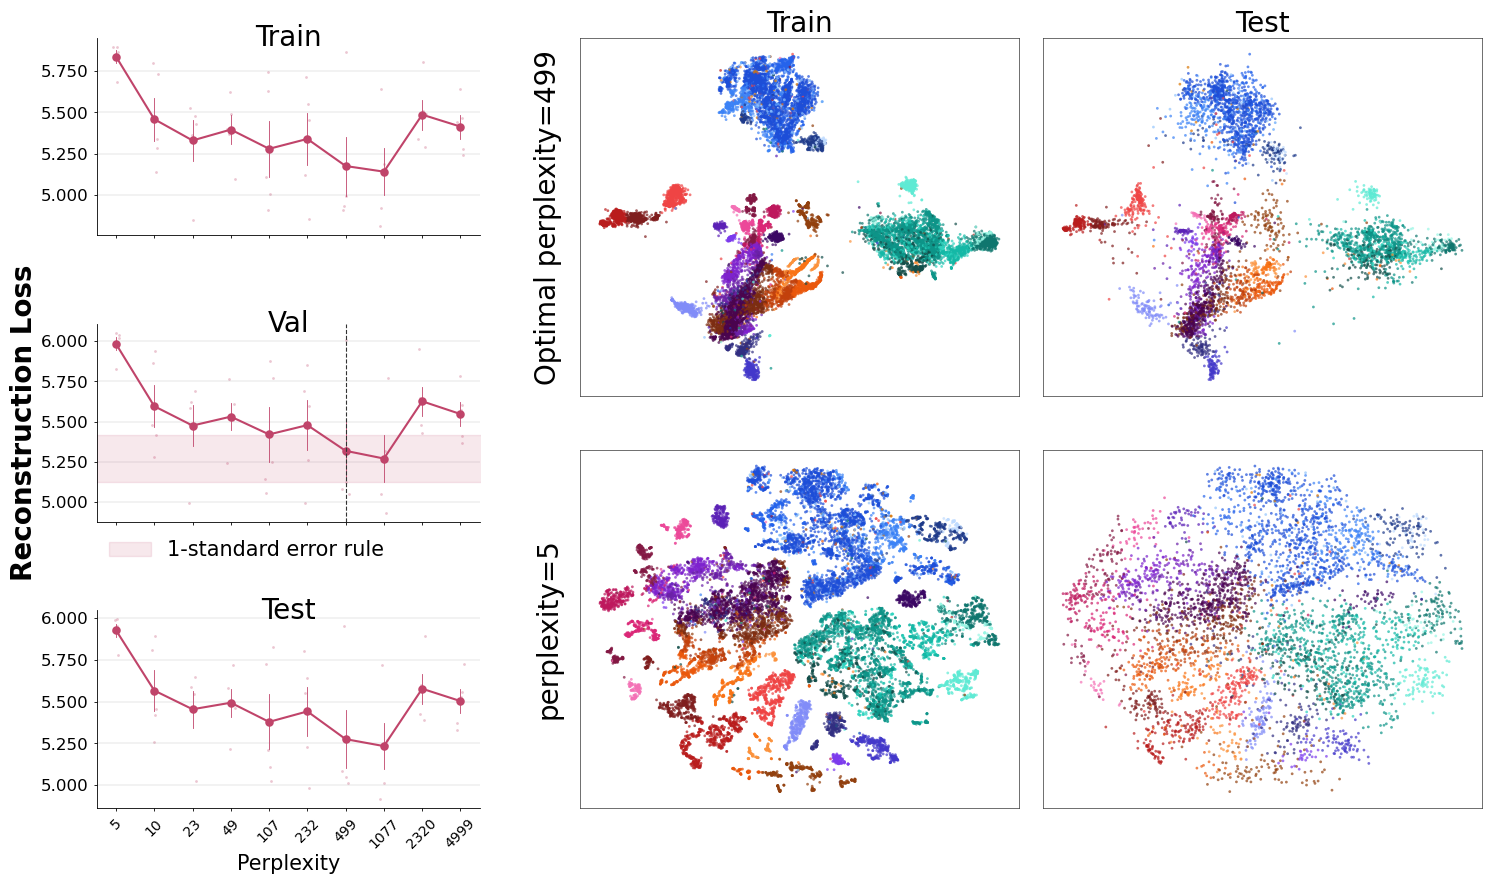

In [77]:
build_figure(
    analysis, 'perplexity', unique_perplexities, tsne_one_std_range, vline_x,
    emb_data, list_tsne_param, tsne_one_std_param_choice,
    hydra_palette, 'perplexity', 'Perplexity',
    row_label_y=1,
    legend_kw={'frameon': False, 'fontsize': 15, 'loc': 'best', 'bbox_to_anchor': (0.8, 0)},
    xtick_fontsize=10, show_boxplot=False, figsize=(18, 10),
)

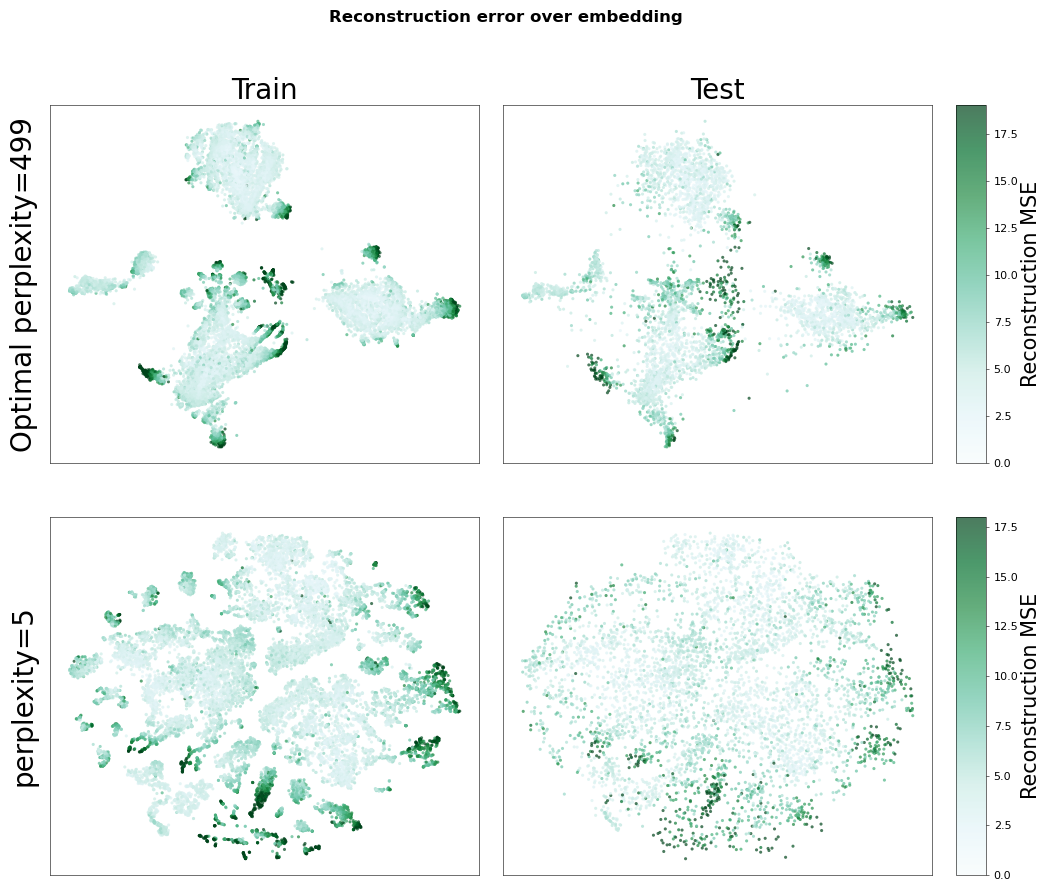

In [78]:
build_distortion_figure(
    emb_data, list_tsne_param, tsne_one_std_param_choice,
    param_label='perplexity', cmap=sns.color_palette("BuGn", as_cmap=True), figsize=(12, 10),
)

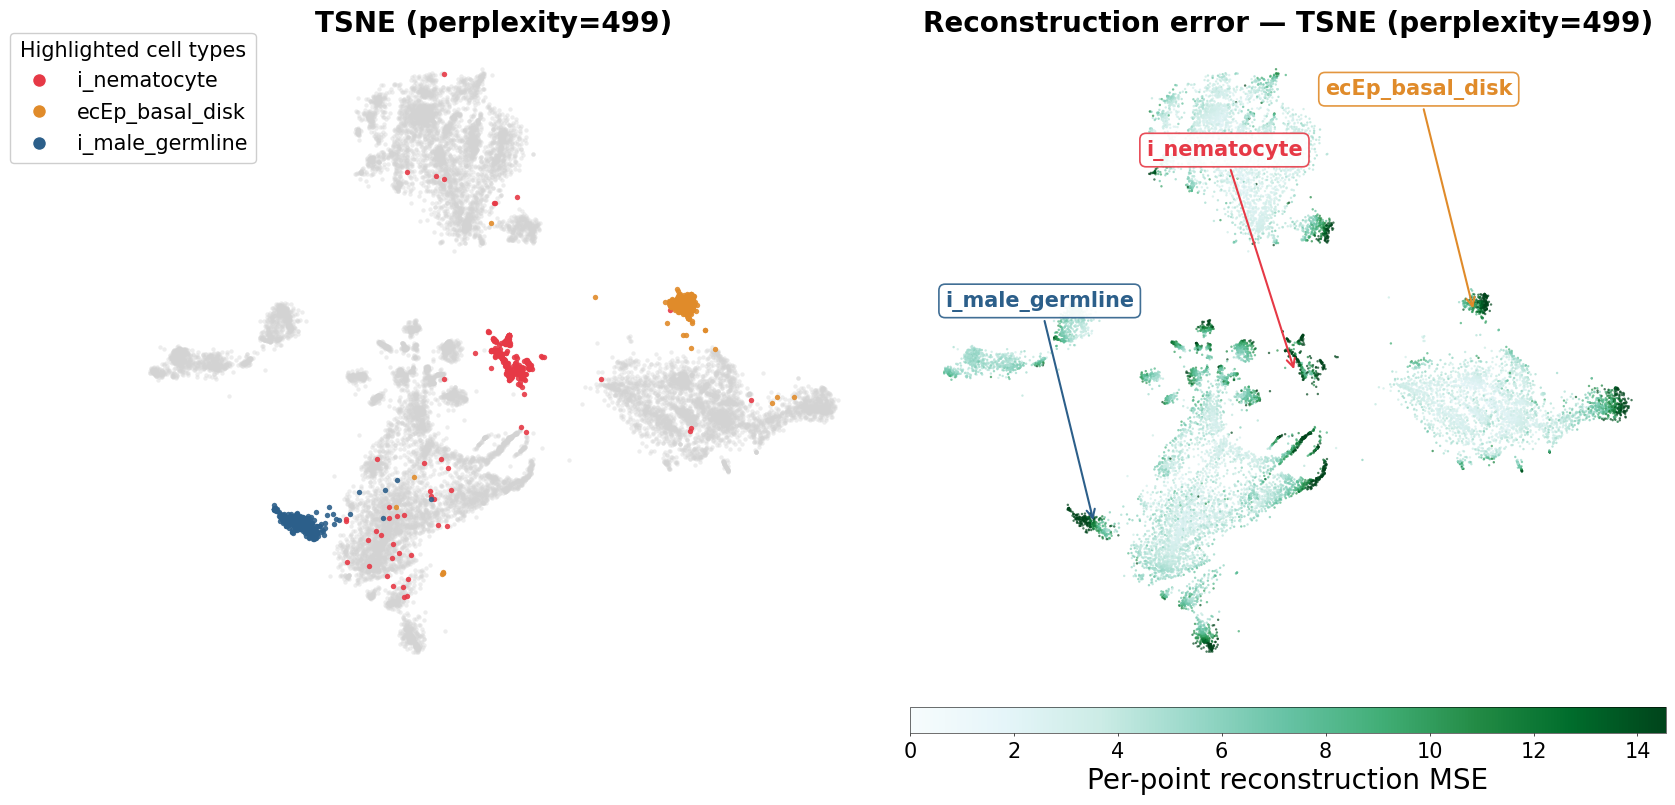

In [90]:
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family':      'sans-serif',
    'font.sans-serif':  ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':        11,
    'pdf.fonttype':     42,
    'ps.fonttype':      42,
})

# ── Shared colorscale across both perplexities ────────────────────────────────
all_recon   = np.concatenate([per_sample_recon_tsne01, per_sample_recon_tsne02])
vmax_shared = np.quantile(all_recon, 0.95)
shared_norm = plt.Normalize(vmin=0, vmax=vmax_shared)
cmap        = sns.color_palette("BuGn", as_cmap=True)

highlight_cts = {
    'i_nematocyte':    '#E63946',
    'ecEp_basal_disk': '#E08B2A',
    'i_male_germline': '#2C5F8A',
}

# ── Layout ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 9))
# gs  = GridSpec(3, 2, figure=fig,
#                height_ratios=[1, 1, 0.04],
#                hspace=0.08, wspace=0.05)
gs  = GridSpec(2, 2, figure=fig,
               height_ratios=[1, 0.04],
               hspace=0.08, wspace=0.05)

ax_p1_cell  = fig.add_subplot(gs[0, 0])
ax_p1_recon = fig.add_subplot(gs[0, 1])
# ax_p5_cell  = fig.add_subplot(gs[1, 0])
# ax_p5_recon = fig.add_subplot(gs[1, 1])
# cax         = fig.add_subplot(gs[2, :])
cax         = fig.add_subplot(gs[1, 1])

panels = [
    (ax_p1_cell, ax_p1_recon,
     student_embed_tsne01, per_sample_recon_tsne01,
     f'TSNE (perplexity={tsne_one_std_param_choice})',
     f'Reconstruction error — TSNE (perplexity={tsne_one_std_param_choice})'),
#     (ax_p5_cell, ax_p5_recon,
#      student_embed_tsne02, per_sample_recon_tsne02,
#      f'TSNE (perplexity={list_tsne_param[1]})',
#      f'Reconstruction error — TSNE (perplexity={list_tsne_param[1]})'),
]

# ── Panels ────────────────────────────────────────────────────────────────────
highlight_mask_global = np.isin(y, list(highlight_cts.keys()))

for ax_cell, ax_recon, embed, recon, cell_label, recon_label in panels:
    Z = embed.detach().numpy() if hasattr(embed, 'detach') else np.array(embed)
    highlight_mask = np.isin(y, list(highlight_cts.keys()))

    # ── left: gray background + highlighted cell types ────────────────────────
    ax_cell.scatter(
        Z[~highlight_mask, 0], Z[~highlight_mask, 1],
        c='#d3d3d3', s=10, alpha=0.4, linewidths=0,
        rasterized=True, zorder=1,
    )
    for ct, color in highlight_cts.items():
        mask = y == ct
        if mask.sum() == 0:
            continue
        ax_cell.scatter(
            Z[mask, 0], Z[mask, 1],
            c=color, s=15, alpha=0.9, linewidths=0,
            rasterized=True, zorder=2,
        )

    ax_cell.axis('off')
    ax_cell.set_title(cell_label, fontsize=20, fontweight='bold', pad=6)

    # ── right: reconstruction loss colored ───────────────────────────────────
    ax_recon.scatter(
        Z[:, 0], Z[:, 1],
        c=recon, cmap=cmap, norm=shared_norm,
        s=3, alpha=0.7, linewidths=0, rasterized=True,
    )

    # annotations on recon panel only
    for ct, color in highlight_cts.items():
        mask = y == ct
        if mask.sum() == 0:
            continue
        cx = Z[mask, 0].mean()
        cy = Z[mask, 1].mean()
        ax_recon.annotate(
            ct, #.replace('_', ' ')
            xy=(cx, cy),
            xytext=(cx - Z[:, 0].std(),
                    cy + 1.5*Z[:, 1].std()),
            fontsize=15, fontweight='bold', color=color,
            arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', fc='white',
                      ec=color, alpha=0.9, lw=1.2),
        )

    ax_recon.axis('off')
    ax_recon.set_title(recon_label, fontsize=20, fontweight='bold', pad=6)

# ── Shared colorbar ───────────────────────────────────────────────────────────
sm = plt.cm.ScalarMappable(cmap=cmap, norm=shared_norm)
cb = fig.colorbar(sm, cax=cax, orientation='horizontal')
cb.set_label('Per-point reconstruction MSE', fontsize=20)
cb.ax.tick_params(labelsize=15, width=0.5, length=2.5)
cb.outline.set_linewidth(0.4)

# ── Legend for highlighted cell types ─────────────────────────────────────────
legend_handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor=color, markersize=10,
           label=ct)
    for ct, color in highlight_cts.items()
]
fig.legend(
    handles=legend_handles,
    loc='upper right', bbox_to_anchor=(0.2, 0.9),
    frameon=True, facecolor='white', edgecolor='#cccccc',
    framealpha=0.95,
    fontsize=15, title='Highlighted cell types', title_fontsize=15,
)

# fig.suptitle('Reconstruction error highlights biologically distinct cell states',
#              fontsize=30, y=1)

plt.show()

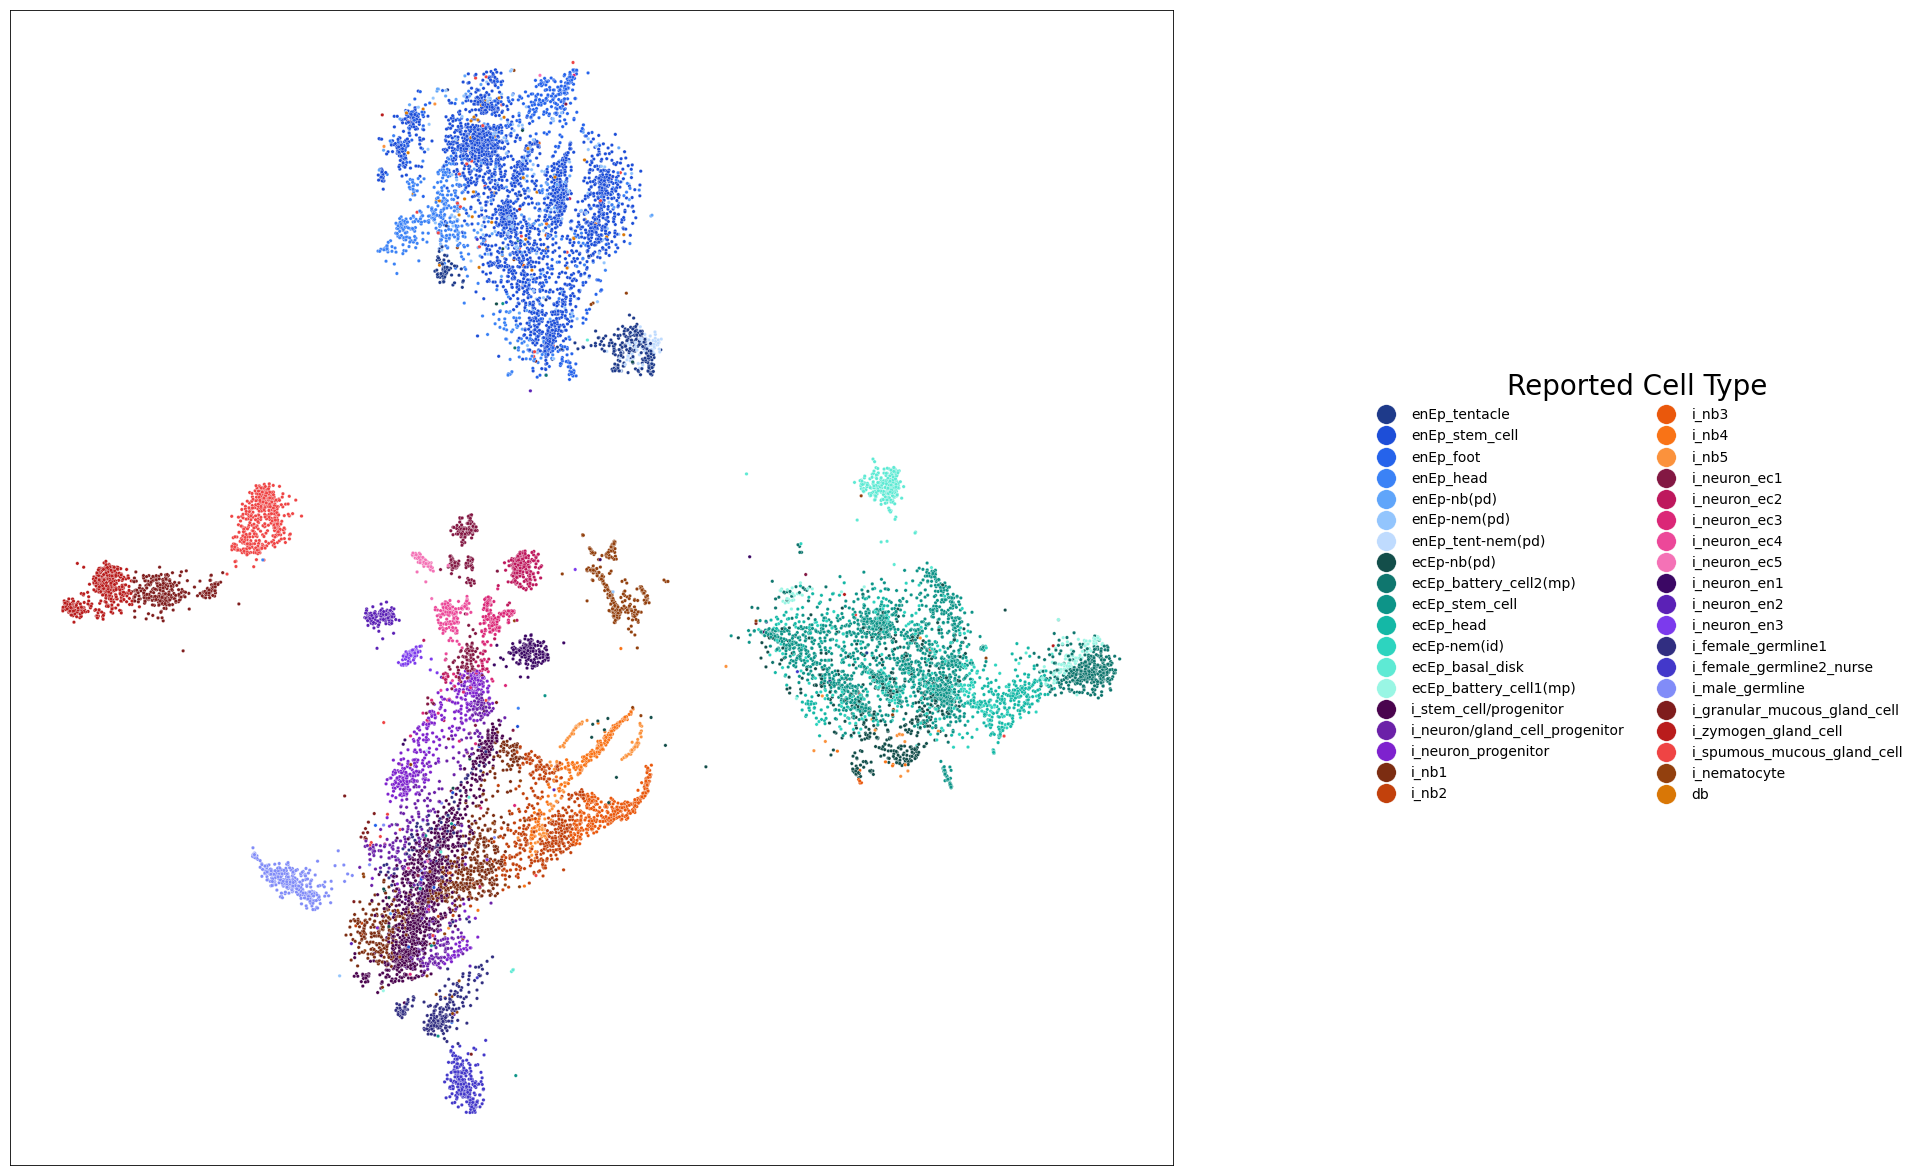

In [42]:
plt.figure(figsize=(15,15))
embedding = student_embed_tsne01
sns.scatterplot(x = embedding.detach().numpy()[:, 0], 
                y = embedding.detach().numpy()[:, 1], hue = y, 
                palette=hydra_palette, legend=True, size=2)
handles, labels = plt.gca().get_legend_handles_labels()

# map current legend labels to handles
handle_dict = dict(zip(labels, handles))
ordered_labels = [lab for lab in hydra_palette.keys() if lab in handle_dict]
ordered_handles = [handle_dict[lab] for lab in ordered_labels]

plt.legend(ordered_handles, ordered_labels, loc='center', bbox_to_anchor=(1.4, 0.5), frameon=False, title='Reported Cell Type', ncol=2, fontsize=10, markerscale=4, title_fontsize=20)
plt.xticks([]); plt.yticks([])
plt.show()

In [15]:
hydra_umap_res_dict = []
for s in range(5):
    for n in np.unique(np.logspace(np.log10(5), np.log10(2000), 10).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_umap_{n}_0.1_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_umap_{n}_0.1_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/hydra/medal_umap2_{n}_0.1_tc0_{s}_ckpts/final.pt",
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2,
                batchnorm=True)
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)

        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            hydra_umap_res_dict.append({"n_neighbors": n, "recon_loss": train_recon, "split": "Train", "seed": s})

            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            hydra_umap_res_dict.append({"n_neighbors": n, "recon_loss": val_recon, "split": "Val", "seed": s})
            
            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            hydra_umap_res_dict.append({"n_neighbors": n, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {n} seed {s} due to distillation loss {train_distill}")
            
analysis, umap_one_std_range, umap_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(hydra_umap_res_dict, 'n_neighbors')

/tmp/ipykernel_44296/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded par

In [5]:
# ── Load student models & compute embeddings ─────────────────────────────────────────────
list_umap_param = [271, 2000]
student_umap01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_umap2_{list_umap_param[0]}_0.1_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_umap01, student_embed_umap01 = student_umap01(torch.tensor(X, dtype=torch.float32))
student_recon_val_umap01, student_embed_val_umap01 = student_umap01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_umap01, student_embed_test_umap01 = student_umap01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_umap01 = np.mean((student_recon_umap01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_umap01 = np.mean((student_recon_val_umap01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_umap01 = np.mean((student_recon_test_umap01.detach().numpy() - X_test)**2, axis=1)

student_umap02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_umap2_{list_umap_param[1]}_0.1_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_umap02, student_embed_umap02 = student_umap02(torch.tensor(X, dtype=torch.float32))
student_recon_val_umap02, student_embed_val_umap02 = student_umap02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_umap02, student_embed_test_umap02 = student_umap02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_umap02 = np.mean((student_recon_umap02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_umap02 = np.mean((student_recon_val_umap02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_umap02 = np.mean((student_recon_test_umap02.detach().numpy() - X_test)**2, axis=1)

# ── Figure ──────────────────────────────────────────────────────────────────────────────────────────────────────────
emb_data = {
    list_umap_param[0]: {
        'Train': (student_embed_umap01,      per_sample_recon_umap01,      y),
        'Val':   (student_embed_val_umap01,  per_sample_recon_val_umap01,  y_val),
        'Test':  (student_embed_test_umap01, per_sample_recon_test_umap01, y_test),
    },
    list_umap_param[1]: {
        'Train': (student_embed_umap02,      per_sample_recon_umap02,      y),
        'Val':   (student_embed_val_umap02,  per_sample_recon_val_umap02,  y_val),
        'Test':  (student_embed_test_umap02, per_sample_recon_test_umap02, y_test),
    },
}


/tmp/ipykernel_10560/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0


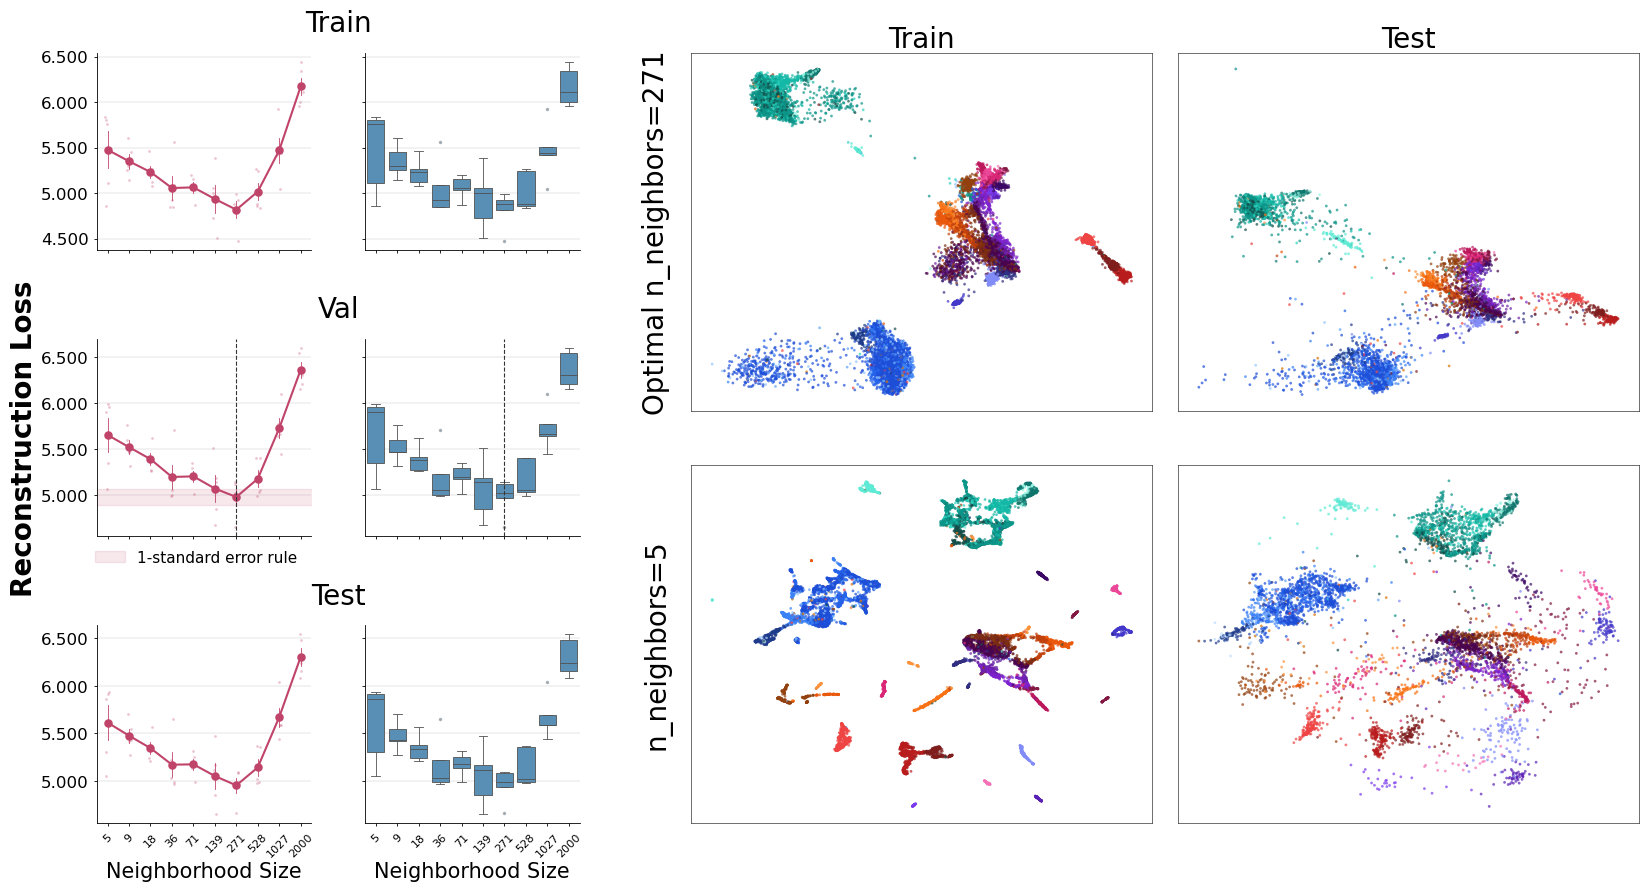

In [23]:
build_figure(
    analysis, 'n_neighbors', unique_neighbors, umap_one_std_range, vline_x,
    emb_data, [umap_one_std_param_choice, list_umap_param[1]], umap_one_std_param_choice,
    hydra_palette, 'n_neighbors', 'Neighborhood Size',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'best', 'bbox_to_anchor': (1, 0)},
    xtick_fontsize=8, figsize=(20, 10)
)

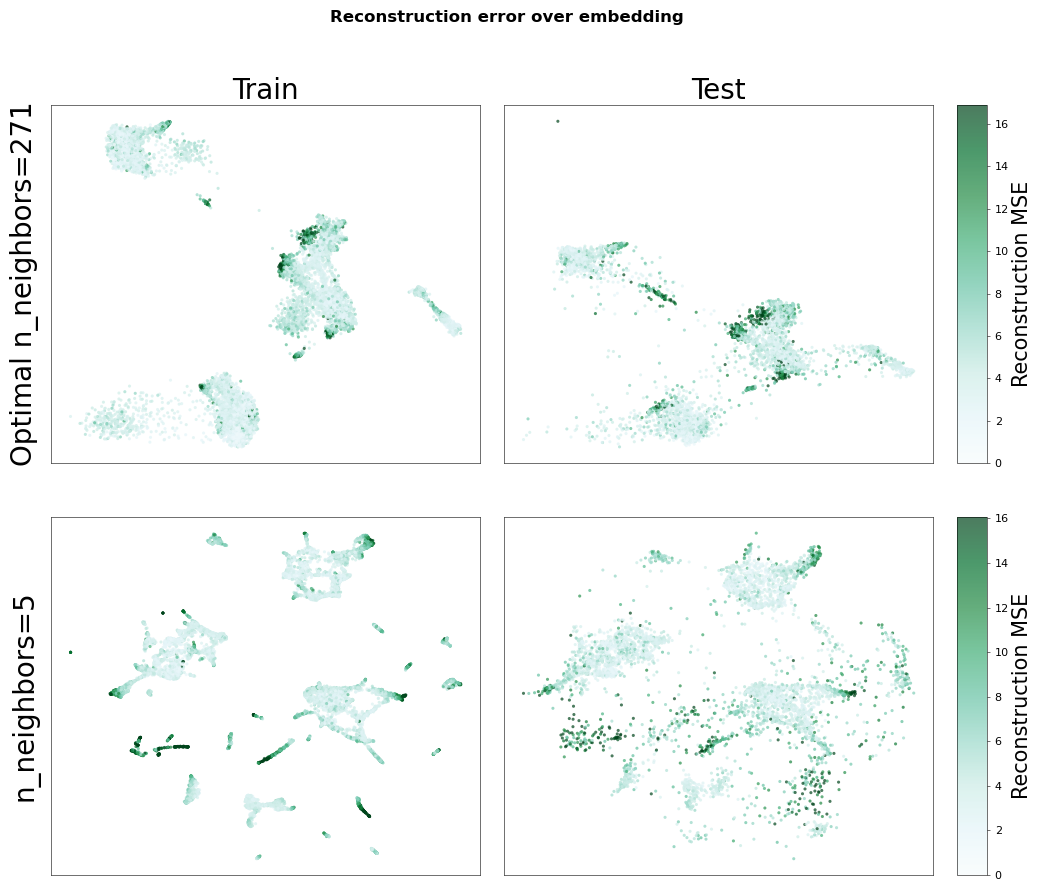

In [24]:
build_distortion_figure(
    emb_data, [umap_one_std_param_choice, list_umap_param[1]], umap_one_std_param_choice,
    param_label='n_neighbors', cmap=sns.color_palette("BuGn", as_cmap=True), figsize=(12, 10),
)

In [7]:
hydra_spectral_res_dict = []
for s in range(5):
    for n in np.unique(np.logspace(np.log10(5), np.log10(200), 15).astype(int)):
        teacher_embed_raw = np.load(
            Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_spectral2_{n}_0_train.npy"
        )
        norm = GlobalEmbeddingNormalizer.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_spectral2_{n}_0_train.norm.pkl")
        teacher_embed = norm.transform(teacher_embed_raw)
        student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/hydra/medal_spectral2_{n}_tc0_{s}_ckpts/final.pt",
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)
        
        student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
        train_distill = np.mean((teacher_embed - student_embed.detach().numpy()) ** 2)
        if train_distill < 1e-5:
            train_recon = np.mean((student_recon.detach().numpy() - X)**2)
            hydra_spectral_res_dict.append({"n_neighbors": n, "recon_loss": train_recon, "split": "Train", "seed": s})
            
            x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
            val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
            hydra_spectral_res_dict.append({"n_neighbors": n, "recon_loss": val_recon, "split": "Val", "seed": s})

            x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
            test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
            hydra_spectral_res_dict.append({"n_neighbors": n, "recon_loss": test_recon, "split": "Test", "seed": s})
        else:
            print(f"Skipping param {n} seed {s} due to distillation loss {train_distill}")

/tmp/ipykernel_12604/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded par

/tmp/ipykernel_12604/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0


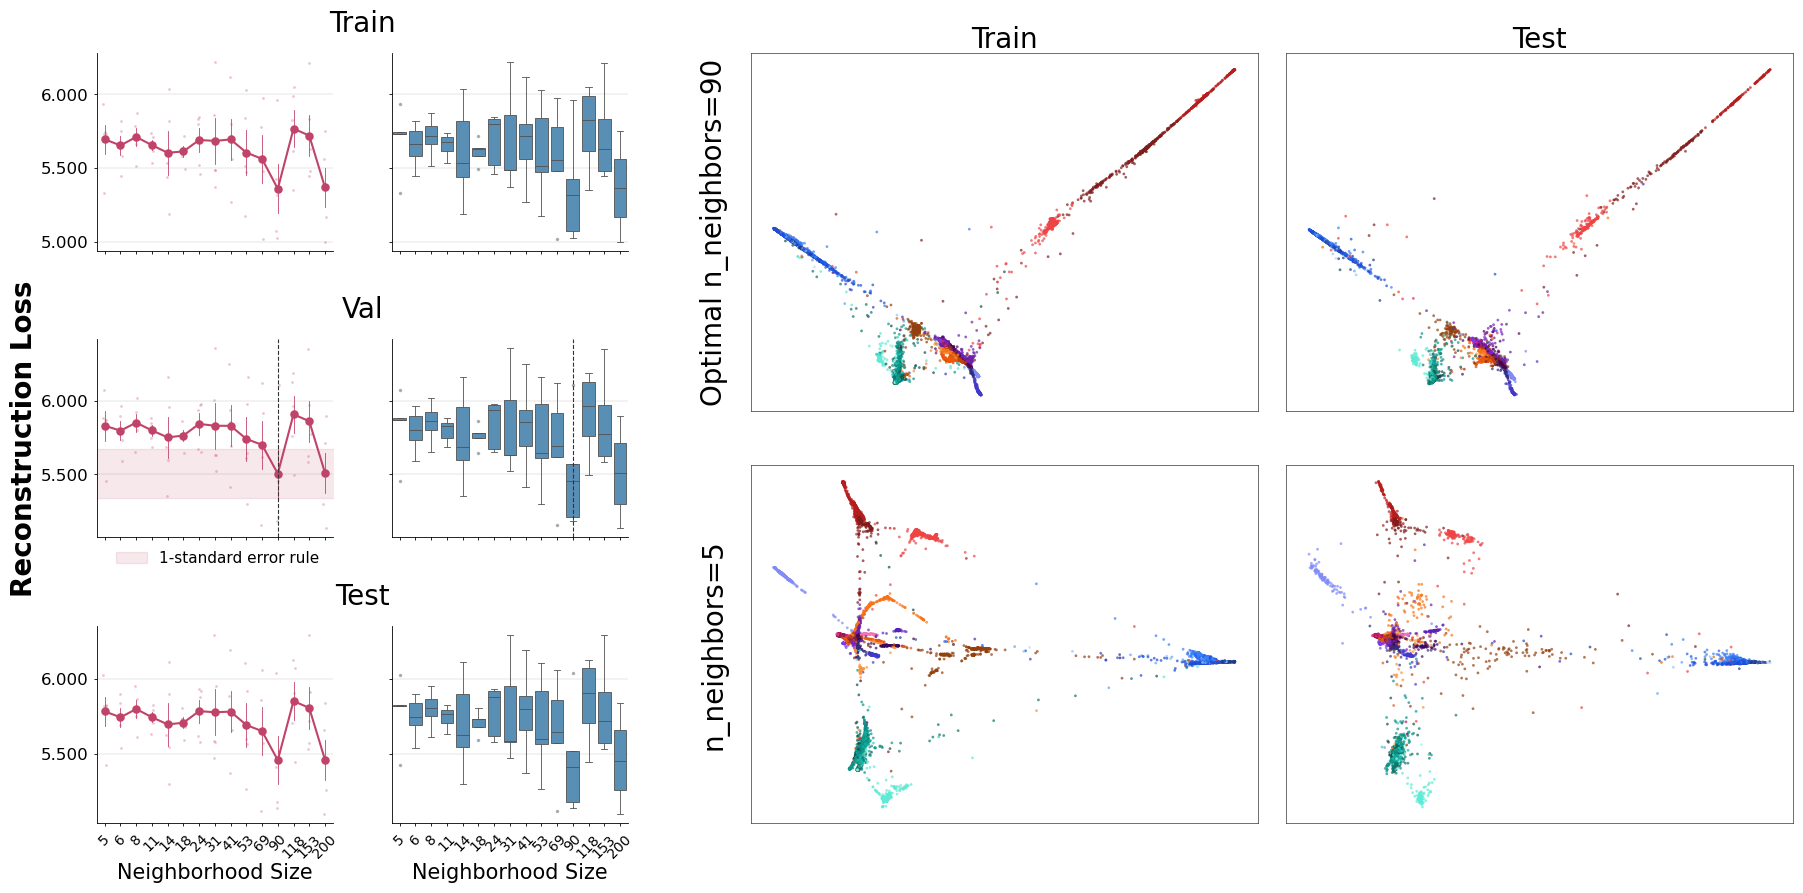

In [29]:
analysis, spectral_one_std_range, spectral_one_std_param_choice, unique_neighbors, vline_x = \
    compute_param_choice(hydra_spectral_res_dict, 'n_neighbors')

# ── Load student models & compute embeddings ─────────────────────────────────────────────
list_spectral_param = [spectral_one_std_param_choice, 5]
student_spectral01 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_spectral2_{list_spectral_param[0]}_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_spectral01, student_embed_spectral01 = student_spectral01(torch.tensor(X, dtype=torch.float32))
student_recon_val_spectral01, student_embed_val_spectral01 = student_spectral01(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_spectral01, student_embed_test_spectral01 = student_spectral01(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_spectral01 = np.mean((student_recon_spectral01.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_spectral01 = np.mean((student_recon_val_spectral01.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_spectral01 = np.mean((student_recon_test_spectral01.detach().numpy() - X_test)**2, axis=1)

student_spectral02 = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_spectral2_{list_spectral_param[1]}_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_spectral02, student_embed_spectral02 = student_spectral02(torch.tensor(X, dtype=torch.float32))
student_recon_val_spectral02, student_embed_val_spectral02 = student_spectral02(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_spectral02, student_embed_test_spectral02 = student_spectral02(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_spectral02 = np.mean((student_recon_spectral02.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_spectral02 = np.mean((student_recon_val_spectral02.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_spectral02 = np.mean((student_recon_test_spectral02.detach().numpy() - X_test)**2, axis=1)

emb_data = {
    spectral_one_std_param_choice: {
        'Train': (student_embed_spectral01,      per_sample_recon_spectral01,      y),
        'Val':   (student_embed_val_spectral01,  per_sample_recon_val_spectral01,  y_val),
        'Test':  (student_embed_test_spectral01, per_sample_recon_test_spectral01, y_test),
    },
    list_spectral_param[1]: {
        'Train': (student_embed_spectral02,      per_sample_recon_spectral02,      y),
        'Val':   (student_embed_val_spectral02,  per_sample_recon_val_spectral02,  y_val),
        'Test':  (student_embed_test_spectral02, per_sample_recon_test_spectral02, y_test),
    },
}

build_figure(
    analysis, 'n_neighbors', unique_neighbors, spectral_one_std_range, vline_x,
    emb_data, [spectral_one_std_param_choice, list_spectral_param[1]], spectral_one_std_param_choice,
    hydra_palette, 'n_neighbors', 'Neighborhood Size',
    row_label_y=1.15,
    legend_kw={'frameon': False, 'fontsize': 11, 'loc': 'best', 'bbox_to_anchor': (1, 0)},
    xtick_fontsize=10, figsize=(22,10),
    share_x_lines=False,
)

In [11]:
hydra_pca_res_dict = []
for s in range(5):
    student = load_trained_ae(Path(PATH_PREFIX) / f"drd_data/tmp_results/normalize/hydra/medal_pca2_tc0_{s}_ckpts/final.pt",
                                  input_dim=500,
                                  hidden_dims=[256, 1024, 1024, 1024],
                                  latent_dim=2, batchnorm=True)
    
    student_recon, student_embed = student(torch.tensor(X, dtype=torch.float32))
    train_recon = np.mean((student_recon.detach().numpy() - X)**2)
    hydra_pca_res_dict.append({"recon_loss": train_recon, "split": "Train", "seed": s})
    
    x_val_recon, _ = student(torch.tensor(X_val, dtype=torch.float32))
    val_recon = np.mean((x_val_recon.detach().numpy() - X_val)**2)
    hydra_pca_res_dict.append({"recon_loss": val_recon, "split": "Val", "seed": s})

    x_test_recon, _ = student(torch.tensor(X_test, dtype=torch.float32))
    test_recon = np.mean((x_test_recon.detach().numpy() - X_test)**2)
    hydra_pca_res_dict.append({"recon_loss": test_recon, "split": "Test", "seed": s})

/tmp/ipykernel_12604/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0
loaded params: 40 | missing=0 | unexpected=0


In [9]:
student_pca = load_trained_ae(Path(PATH_PREFIX) / f'drd_data/tmp_results/normalize/hydra/medal_pca2_tc0_0_ckpts/final.pt',
                input_dim=500,
                hidden_dims=[256, 1024, 1024, 1024],
                latent_dim=2, batchnorm=True)

student_recon_pca, student_embed_pca = student_pca(torch.tensor(X, dtype=torch.float32))
student_recon_val_pca, student_embed_val_pca = student_pca(torch.tensor(X_val, dtype=torch.float32))
student_recon_test_pca, student_embed_test_pca = student_pca(torch.tensor(X_test, dtype=torch.float32))
per_sample_recon_pca = np.mean((student_recon_pca.detach().numpy() - X)**2, axis=1)
per_sample_recon_val_pca = np.mean((student_recon_val_pca.detach().numpy() - X_val)**2, axis=1)
per_sample_recon_test_pca = np.mean((student_recon_test_pca.detach().numpy() - X_test)**2, axis=1)

/tmp/ipykernel_6613/1580406936.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(ckpt_path, map_location="cpu")


loaded params: 40 | missing=0 | unexpected=0


In [16]:
tsne_analysis = pd.DataFrame(hydra_tsne_res_dict)
tsne_analysis = tsne_analysis.loc[(tsne_analysis.split=='Val'),:]
tsne_analysis_agg = tsne_analysis.loc[:, ['perplexity','recon_loss']].groupby('perplexity').agg('mean').reset_index()
umap_analysis = pd.DataFrame(hydra_umap_res_dict)
umap_analysis = umap_analysis.loc[(umap_analysis.split=='Val'), :]
umap_analysis_agg = umap_analysis.loc[:, ['n_neighbors','recon_loss']].groupby('n_neighbors').agg('mean').reset_index()
spectral_analysis = pd.DataFrame(hydra_spectral_res_dict)
spectral_analysis = spectral_analysis.loc[(spectral_analysis.split=='Val'), :]
spectral_analysis_agg = spectral_analysis.loc[:, ['n_neighbors','recon_loss']].groupby('n_neighbors').agg('mean').reset_index()
pca_analysis = pd.DataFrame(hydra_pca_res_dict)
pca_analysis = pca_analysis.loc[(pca_analysis.split=='Val'), :]

tsne_best = tsne_analysis.loc[tsne_analysis.perplexity == tsne_one_std_param_choice, ['recon_loss', 'seed']]
tsne_best['method'] = f'TSNE(perplexity={tsne_one_std_param_choice})'
umap_best = umap_analysis.loc[umap_analysis.n_neighbors == umap_one_std_param_choice, ['recon_loss', 'seed']]
umap_best['method'] = f'UMAP(n_neighbors={umap_one_std_param_choice})'
spectral_best = spectral_analysis.loc[spectral_analysis.n_neighbors == spectral_one_std_param_choice, ['recon_loss', 'seed']]
spectral_best['method'] = f'Spectral(n_neighbors={spectral_one_std_param_choice})'
pca_best = pca_analysis[['recon_loss', 'seed']]
pca_best['method'] = 'PCA'
teachers = pd.concat([tsne_best, umap_best, spectral_best, pca_best])


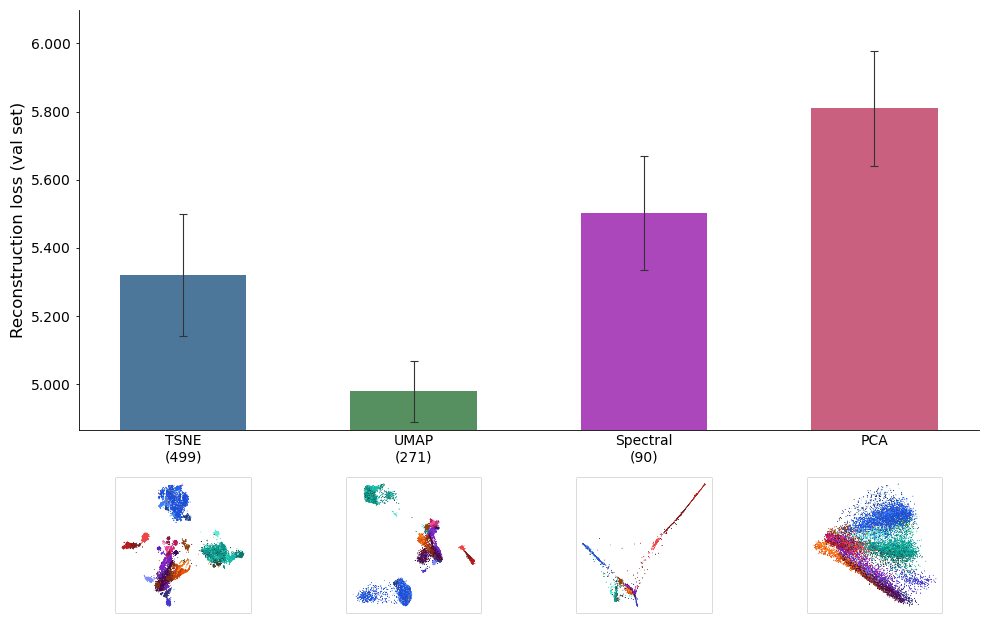

In [19]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# --- assumes embeddings dict like: {'TSNE(793)': Z_array, ...} ---
# Z_arrays should be (N,2) numpy arrays, already computed
embeddings = {
    f'TSNE(perplexity={tsne_one_std_param_choice})': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_tsne_{tsne_one_std_param_choice}_0_train.npy"),
    f'UMAP(n_neighbors={umap_one_std_param_choice})':np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_umap_{umap_one_std_param_choice}_0.1_0_train.npy"),
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_spectral2_{spectral_one_std_param_choice}_0_train.npy"),
    'PCA': np.load(Path(PATH_PREFIX) / f"drd_data/embeddings2/hydra_pca2_0_train.npy"),
}

method_order = [f'TSNE(perplexity={tsne_one_std_param_choice})', f'UMAP(n_neighbors={umap_one_std_param_choice})',
                f'Spectral(n_neighbors={spectral_one_std_param_choice})', 'PCA', 
               ]

short_labels = {
    f'TSNE(perplexity={tsne_one_std_param_choice})':  f'TSNE\n({tsne_one_std_param_choice})',
    f'UMAP(n_neighbors={umap_one_std_param_choice})':  f'UMAP\n({umap_one_std_param_choice})',
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': f'Spectral\n({spectral_one_std_param_choice})',
    'PCA':                   'PCA',
}

# color palette — one color per method, muted
method_colors = {
    f'TSNE(perplexity={tsne_one_std_param_choice})':  '#2C5F8A',
    f'UMAP(n_neighbors={umap_one_std_param_choice})':  '#3A7D44',
    f'Spectral(n_neighbors={spectral_one_std_param_choice})': '#9C27B0',
    'PCA':                   '#C0446A',
}

# aggregate stats
stats = (teachers.groupby('method')['recon_loss']
         .agg(mean='mean', se=lambda x: x.sem())
         .reindex(method_order)
         .reset_index())

plt.rcParams.update({
    'font.family':          'sans-serif',
    'font.sans-serif':      ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size':            8,
    'axes.labelsize':       10,
    'axes.titlesize':       12,
    'xtick.labelsize':      10,
    'ytick.labelsize':      10,
    'axes.linewidth':       0.6,
    'xtick.major.width':    0.6,
    'ytick.major.width':    0.6,
    'xtick.major.size':     2.5,
    'ytick.major.size':     2.5,
    'pdf.fonttype':         42,
    'ps.fonttype':          42,
})

# extra bottom margin to accommodate the thumbnails
fig, ax = plt.subplots(figsize=(12, 7))   # bigger
fig.subplots_adjust(bottom=0.28)  

x = np.arange(len(method_order))
bar_w = 0.55

bars = ax.bar(
    x, stats['mean'],
    width=bar_w,
    color=[method_colors[m] for m in stats['method']],
    alpha=0.85,
    zorder=3,
)

ax.errorbar(
    x, stats['mean'],
    yerr=stats['se'],
    fmt='none',
    ecolor='#333333',
    elinewidth=0.8,
    capsize=3,
    capthick=0.8,
    zorder=4,
)

# spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

ax.set_ylabel('Reconstruction loss (val set)', labelpad=4, fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(['' ] * len(method_order))  # blank out text
ax.tick_params(axis='x', length=0)             # hide tick marks too

# add method name as small text manually, below where thumbnail will sit
for i, method in enumerate(method_order):
    ax.text(i, -0.01, short_labels[method],
            ha='center', va='top',
            fontsize=10, 
            transform=ax.get_xaxis_transform())

# thumbnail loop — push further down and slightly bigger
thumb_zoom = 0.32
ymin = (stats['mean'] - stats['se']).min()
ax.set_ylim(ymin * 0.995, (stats['mean'] + stats['se']).max() * 1.02)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
fig.subplots_adjust(bottom=0.28, left=0.15)

for i, method in enumerate(method_order):
    Z = embeddings[method]

    fig_tmp, ax_tmp = plt.subplots(figsize=(3, 3))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1],
                    hue=y, palette=hydra_palette, ax=ax_tmp,
                    legend=False, s=3,
                    linewidths=0, rasterized=True)
    ax_tmp.axis('off')
    fig_tmp.tight_layout(pad=0)
    fig_tmp.canvas.draw()
    img = np.asarray(fig_tmp.canvas.buffer_rgba())[..., :3]  # (H, W, 3)
    plt.close(fig_tmp)

    imagebox = OffsetImage(img, zoom=thumb_zoom)
    ab = AnnotationBbox(
        imagebox,
        xy=(i, 0),
        xycoords=('data', 'axes fraction'),
        box_alignment=(0.5, 1.0),
        xybox=(0, -35),                  # <-- push further down (was -18)
        boxcoords='offset points',
        frameon=True,
        bboxprops=dict(edgecolor='#cccccc', linewidth=0.5,
                       boxstyle='round,pad=0.1'),
    )
    ax.add_artist(ab)
plt.show()

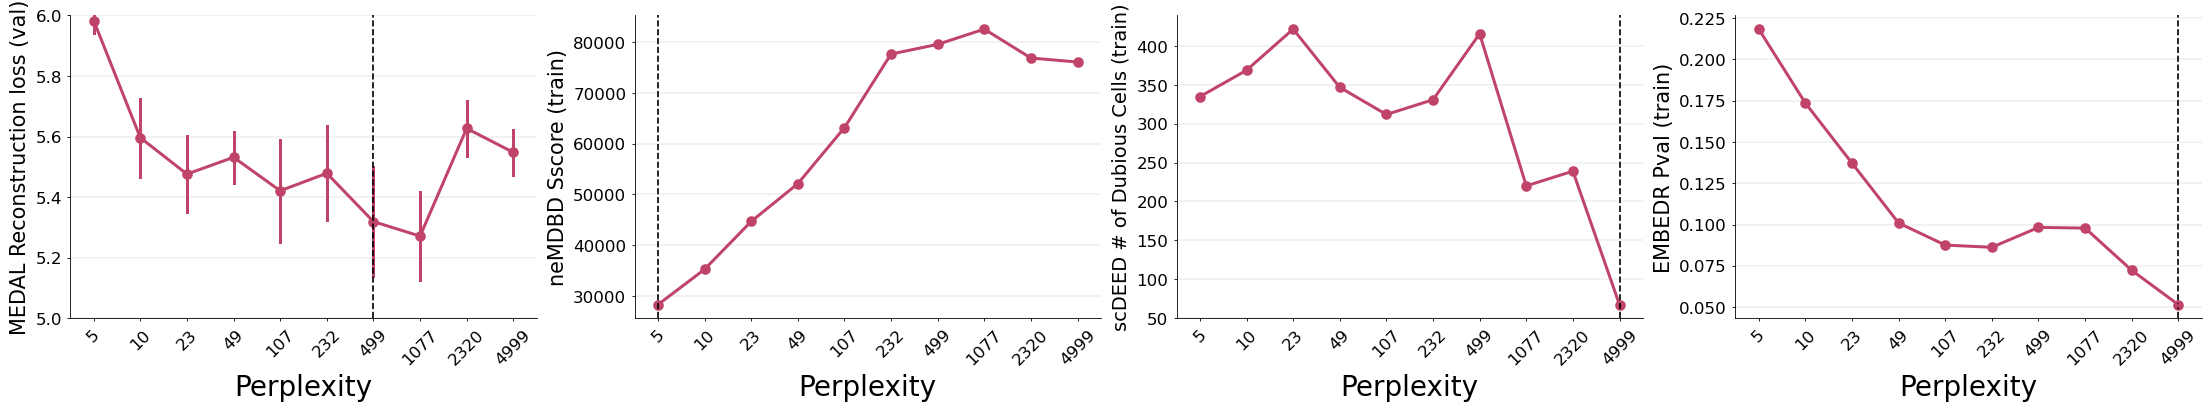

In [33]:
# other methods
fig, axes = plt.subplots(1, 4, figsize=(22,4), constrained_layout=True)
axes_flat = axes.flatten()
## MEDAL
analysis, tsne_one_std_range, tsne_one_std_param_choice, unique_perplexities, vline_x = \
    compute_param_choice(hydra_tsne_res_dict, 'perplexity')
sns.pointplot(data=analysis.loc[analysis.split == "Val"], x="perplexity", y="recon_loss", color="#C0446A", markersize=6, ax=axes_flat[0], 
             errorbar='se')
axes_flat[0].set_ylabel("MEDAL Reconstruction loss (val)", fontsize=15)    
axes_flat[0].axvline(x=unique_perplexities.index(tsne_one_std_param_choice), ls='--', c='black')
axes_flat[0].set_ylim(5, 6)
## PCS Score
pcs_ = pd.read_csv(Path(PATH_PREFIX) / f'MEDAL/comparisons/results_pcs_seed0/hydra_train/elbow_df.csv')
pcs_.sort_values(by='perplexity', inplace=True)
unique_perp = sorted(pcs_['perplexity'].unique())
pcs_tsne_argmin_sscore = pcs_.groupby('perplexity')['mean_sscore'].mean().idxmin()
pos_mean_sscore = unique_perp.index(pcs_tsne_argmin_sscore)
sns.pointplot(data=pcs_, x="perplexity", y="mean_sscore", color="#C0446A", markersize=6, ax=axes_flat[1])
axes_flat[1].set_ylabel("neMDBD Sscore (train)", fontsize=15)    
axes_flat[1].axvline(x=pos_mean_sscore, ls='--', c='black')
## scDEED
scdeed_analysis = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_hydra_train_num_dubious.csv')
umap_argmin = scdeed_analysis['number_dubious_cells'].idxmin()
argmin_position = scdeed_analysis.index.tolist().index(umap_argmin)
sns.pointplot(data=scdeed_analysis, x='perplexity', y='number_dubious_cells', color='#C0446A', markersize=6, ax = axes_flat[2])
axes_flat[2].axvline(x = argmin_position, ls = '--', c ='black')
axes_flat[2].set_ylabel("scDEED # of Dubious Cells (train)", fontsize=14)
## EMBEDR algorithm
embedr_ = pd.read_csv(Path(PATH_PREFIX)/ f'MEDAL/comparisons/results_embedr_tsne_seed0/hydra_train/elbow_df.csv')
embedr_.sort_values(by='perplexity', inplace=True)
embedr_tsne_argmin = embedr_.groupby('perplexity')['mean_embedr_pval'].mean().idxmin()
unique_perp = sorted(embedr_['perplexity'].unique())
pos_mean = unique_perp.index(embedr_tsne_argmin)
sns.pointplot(data=embedr_, x="perplexity", y="mean_embedr_pval", color="#C0446A", markersize=6, ax = axes_flat[3])
sns.stripplot(data=embedr_, x="perplexity", y="mean_embedr_pval", color="#C0446A", size=3, ax = axes_flat[3])
axes_flat[3].set_ylabel("EMBEDR Pval (train)", fontsize=15)       
axes_flat[3].axvline(x=pos_mean, ls='--', c='black')
for ax in axes_flat:
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(0.6)
    ax.grid(axis='y', linewidth=0.35, color='gray', alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=12)
    ax.set_xlabel("Perplexity", fontsize=20)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='center')
plt.show()

In [34]:
methods = ['pcs_ss', 'scdeed', 'embedr']
pcs_ss_best, scdeed_best, embedr_best = 5, 4999, 4999

teacher_embed = dict.fromkeys(methods)
teacher_embed['pcs_ss'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/hydra_tsne_{pcs_ss_best}_0_train_pcs.npy")
teacher_embed['scdeed'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/hydra_train_tsne_{scdeed_best}_0_train_pc4.npy")
teacher_embed['embedr'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/hydra_tsne_{embedr_best}_0_train_embedr.npy").squeeze(0)

#import og indices
pcs_df = pd.read_csv(Path(PATH_PREFIX) /'MEDAL/comparisons/results_pcs_seed0/hydra_train/X_with_best_scores.csv')
per_sample_pcs_ss = pcs_df[f'sscore_meanbest_{pcs_ss_best}']

embedr_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_tsne_seed0/hydra_train/X_with_best_scores.csv')
per_sample_embedr = embedr_df[f'embedr_pval_meanbest_{embedr_best}']

scdeed_df = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_tsne/seed0/tsne_best_hydra_train_full_results.csv", index_col=0)
per_sample_scdeed = split_scdeed_labels(scdeed_df, scdeed_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}



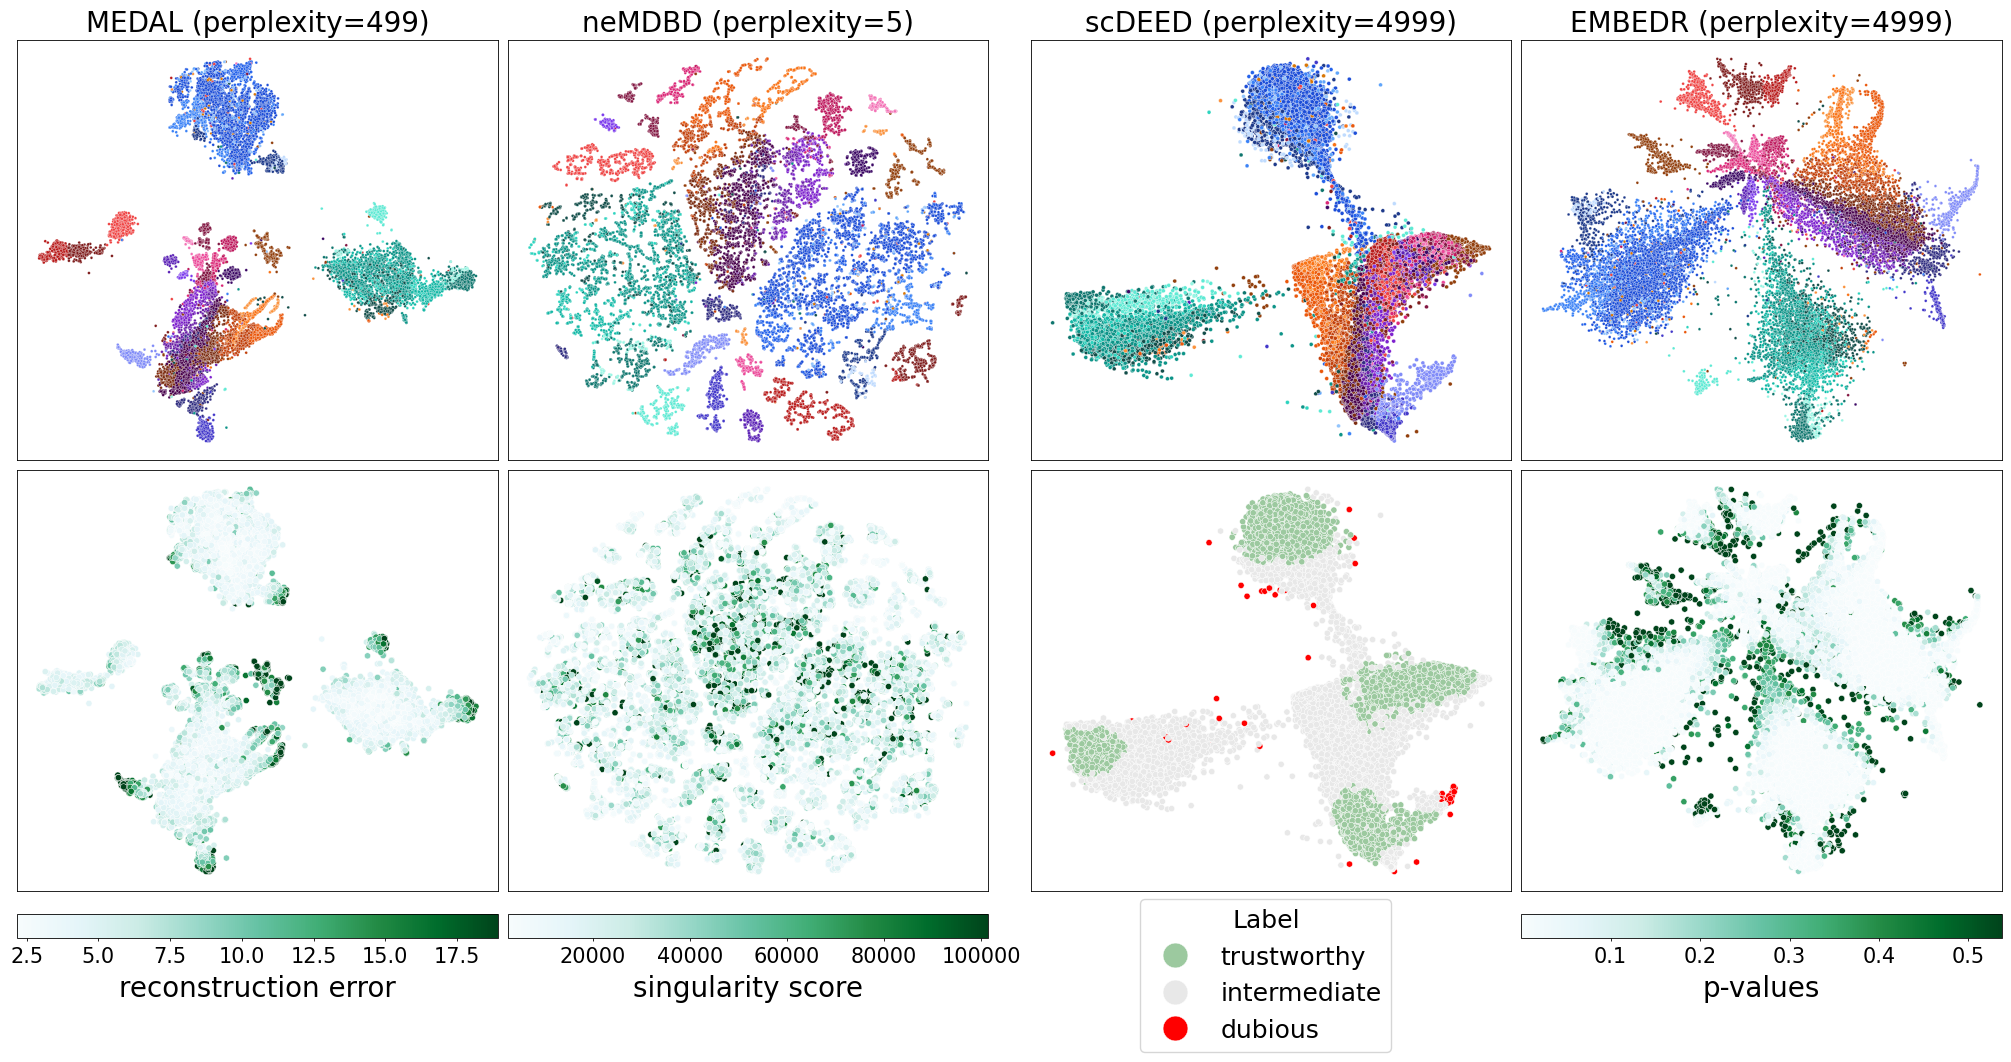

In [38]:
cmap = sns.color_palette("BuGn", as_cmap=True)
fig, axes = plt.subplots(2,4, figsize=(20, 10), constrained_layout=True)
axes_flat = axes.flatten()
# 1st column - MEDAL
medal_data_to_plot = (student_embed_tsne01,      per_sample_recon_tsne01,      y)
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:,0], 
                y=medal_data_to_plot[0].detach().numpy()[:,1], s=4, hue = y, palette=hydra_palette, legend=False, ax = axes_flat[0])
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:,0], 
                y=medal_data_to_plot[0].detach().numpy()[:,1], 
                hue=medal_data_to_plot[1], palette=cmap, 
                hue_norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025), vmax=np.quantile(medal_data_to_plot[1], 0.975)), 
                s=20,legend=False, rasterized=True, ax = axes_flat[4])
axes_flat[0].set_title(f"MEDAL (perplexity={tsne_one_std_param_choice})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025), vmax=np.quantile(medal_data_to_plot[1], 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[4], orientation="horizontal")
cb.set_label("reconstruction error", fontsize=20, labelpad=6)
# 2nd column - PCS Sscore
sns.scatterplot(x=teacher_embed['pcs_ss'][:,0], y=teacher_embed['pcs_ss'][:,1], s=4, hue=y_og, palette=hydra_palette, legend=False, ax = axes_flat[1])
sns.scatterplot(x=teacher_embed['pcs_ss'][:,0], y=teacher_embed['pcs_ss'][:,1], hue=per_sample_pcs_ss, palette=cmap, 
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_pcs_ss, 0.025), vmax=np.quantile(per_sample_pcs_ss, 0.975)), 
                s=20,legend=False, rasterized=True, ax = axes_flat[5])
axes_flat[1].set_title(f"neMDBD (perplexity={pcs_ss_best})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_pcs_ss, 0.025), vmax=np.quantile(per_sample_pcs_ss, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[5], orientation="horizontal")
cb.set_label("singularity score", fontsize=20, labelpad=6)
# 3rd column - scDEED
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[2], s=8, hue = y_og, legend=False, palette=hydra_palette)
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1], 
                ax=axes_flat[6], s=20, hue = per_sample_scdeed, palette = palette_scdeed, legend=True)
handles, labels = axes_flat[6].get_legend_handles_labels()
if getattr(axes_flat[6], "legend_", None) is not None:
    axes_flat[6].legend_.remove()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(0.63, 0.03), frameon=True, title='Label', ncol=1, fontsize=18, markerscale=4, title_fontsize=18)
axes_flat[2].set_title(f"scDEED (perplexity={scdeed_best})", fontsize=20)
# 4th column - EMBEDR Pscore
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], s=4, hue = y_og, palette=hydra_palette, legend=False, ax = axes_flat[3])
sns.scatterplot(x=teacher_embed['embedr'][:,0], y=teacher_embed['embedr'][:,1], hue=per_sample_embedr, palette=cmap, 
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025), vmax=np.quantile(per_sample_embedr, 0.975)), 
                s=20,legend=False, rasterized=True, ax = axes_flat[7])
axes_flat[3].set_title(f"EMBEDR (perplexity={embedr_best})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025), vmax=np.quantile(per_sample_embedr, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[7], orientation="horizontal")
cb.set_label("p-values", fontsize=20, labelpad=6)
for ax in axes_flat:
    ax.set_yticks([])
    ax.set_xticks([])
plt.show()

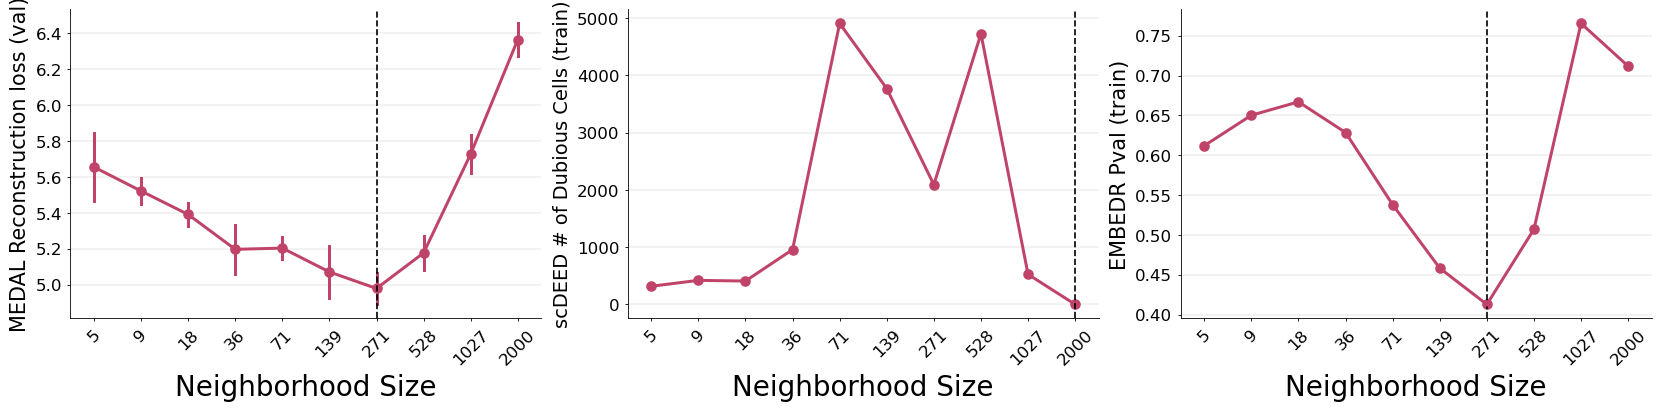

In [29]:
# other methods
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4), constrained_layout=True)
axes_flat = axes.flatten()

## MEDAL
analysis, umap_one_std_range, umap_one_std_param_choice, unique_nn, vline_x = \
    compute_param_choice(hydra_umap_res_dict, 'n_neighbors')
sns.pointplot(data=analysis.loc[analysis.split == "Val"], x="n_neighbors", y="recon_loss", color="#C0446A", markersize=6, ax=axes_flat[0], 
              errorbar='se')
axes_flat[0].set_ylabel("MEDAL Reconstruction loss (val)", fontsize=15)
axes_flat[0].axvline(x=unique_nn.index(umap_one_std_param_choice), ls='--', c='black')

## scDEED
scdeed_analysis = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_scdeed_umap/seed2/umap_best_hydra_train_num_dubious.csv')
umap_argmin = scdeed_analysis['number_dubious_cells'].idxmin()
argmin_position = scdeed_analysis.index.tolist().index(umap_argmin)
sns.pointplot(data=scdeed_analysis, x='n_neighbors', y='number_dubious_cells', color='#C0446A', markersize=6, ax=axes_flat[1])
axes_flat[1].axvline(x=argmin_position, ls='--', c='black')
axes_flat[1].set_ylabel("scDEED # of Dubious Cells (train)", fontsize=14)

## EMBEDR algorithm
embedr_ = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_umap_seed2/hydra_train/elbow_df.csv')
embedr_.sort_values(by='n_neighbors', inplace=True)
embedr_umap_argmin = embedr_.groupby('n_neighbors')['mean_embedr_pval'].mean().idxmin()
unique_nn = sorted(embedr_['n_neighbors'].unique())
pos_mean = unique_nn.index(embedr_umap_argmin)
sns.pointplot(data=embedr_, x="n_neighbors", y="mean_embedr_pval", color="#C0446A", markersize=6, ax=axes_flat[2])
sns.stripplot(data=embedr_, x="n_neighbors", y="mean_embedr_pval", color="#C0446A", size=3, ax=axes_flat[2])
axes_flat[2].set_ylabel("EMBEDR Pval (train)", fontsize=15)
axes_flat[2].axvline(x=pos_mean, ls='--', c='black')

for ax in axes_flat:
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_linewidth(0.6)
    ax.grid(axis='y', linewidth=0.35, color='gray', alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=12)
    ax.set_xlabel("Neighborhood Size", fontsize=20)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='center')

plt.show()

In [ ]:
methods = ['scdeed', 'embedr']
scdeed_best, embedr_best = 2000, 271

teacher_embed = dict.fromkeys(methods)
teacher_embed['scdeed'] = np.load(Path(PATH_PREFIX) / f"MEDAL/comparisons/data/hydra_train_umap_{scdeed_best}_0.1_0_train_pc4.npy")
teacher_embed['embedr'] = np.load(Path(PATH_PREFIX) / f"drd_data/embeddings/hydra_umap_{embedr_best}_0.1_2_train_embedr.npy").squeeze(0)

embedr_df = pd.read_csv(Path(PATH_PREFIX) / 'MEDAL/comparisons/results_embedr_umap_seed2/hydra_train/X_with_best_scores.csv')
per_sample_embedr = embedr_df[f'embedr_pval_meanbest_{embedr_best}']

scdeed_df = pd.read_csv(Path(PATH_PREFIX) / "MEDAL/comparisons/results_scdeed_umap/seed0/umap_best_hydra_train_full_results.csv", index_col=0)
per_sample_scdeed = split_scdeed_labels(scdeed_df, scdeed_best)['label']
palette_scdeed = {'dubious': 'red', 'intermediate': '#e8e8e8', 'trustworthy': "#9cc99f"}



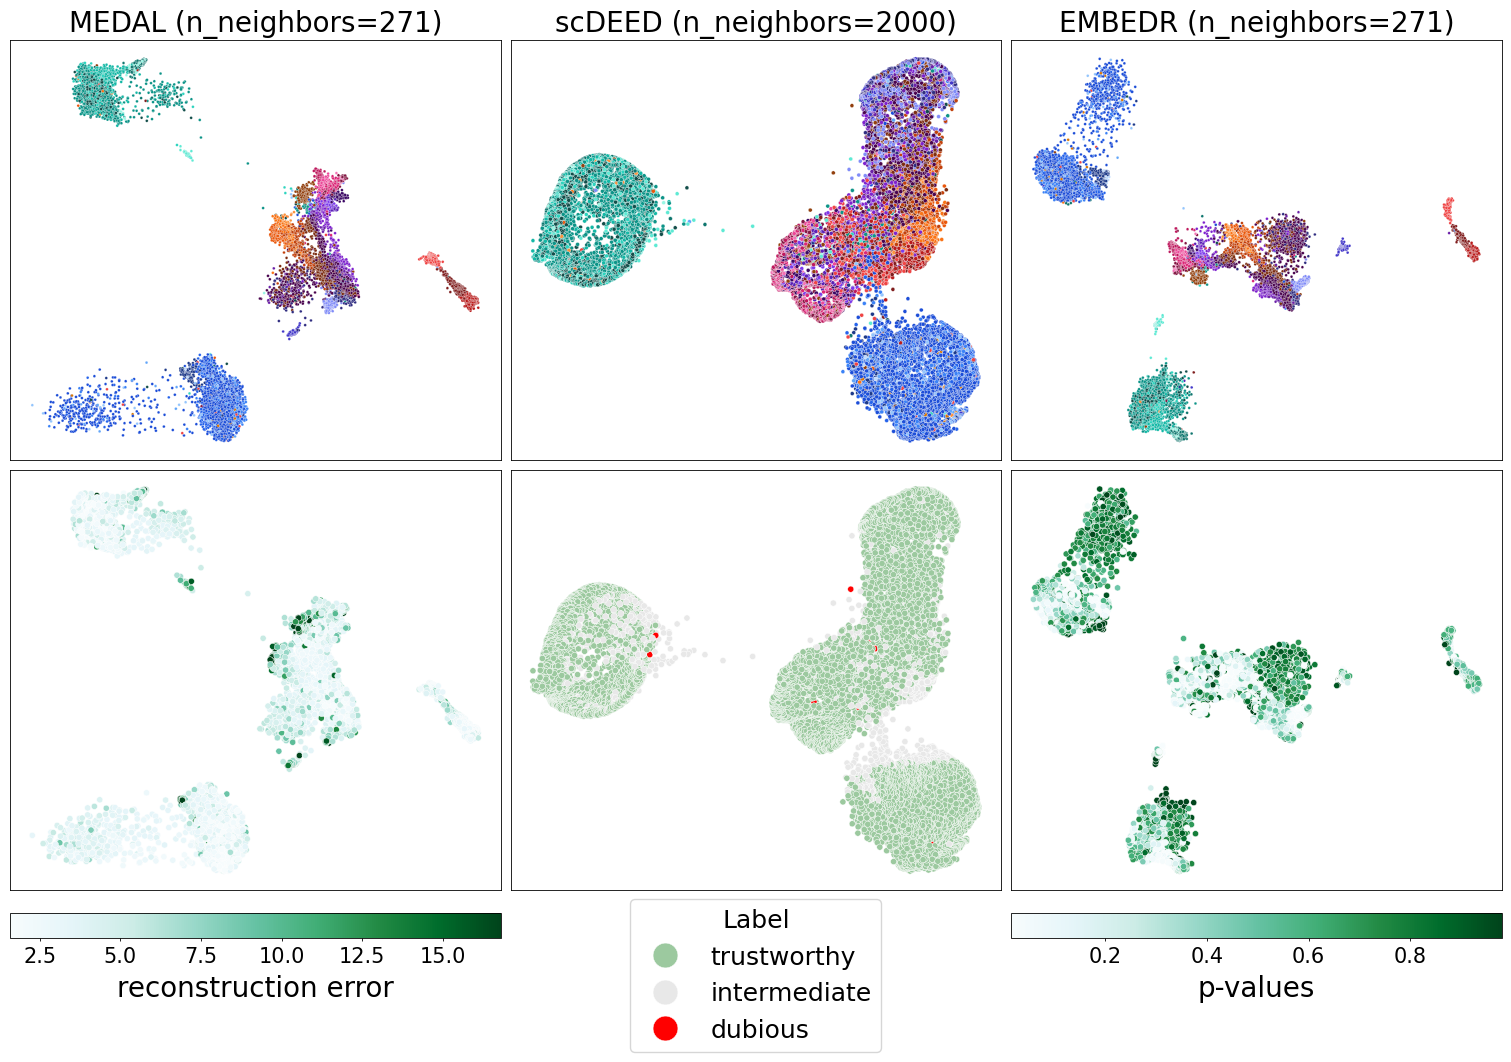

In [30]:
cmap = sns.color_palette("BuGn", as_cmap=True)
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
axes_flat = axes.flatten()

# 1st column - MEDAL
medal_data_to_plot = (student_embed_umap01,  per_sample_recon_umap01,  y)
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:, 0],
                y=medal_data_to_plot[0].detach().numpy()[:, 1],
                s=4, hue=y, palette=hydra_palette, legend=False, ax=axes_flat[0])
sns.scatterplot(x=medal_data_to_plot[0].detach().numpy()[:, 0],
                y=medal_data_to_plot[0].detach().numpy()[:, 1],
                hue=medal_data_to_plot[1], palette=cmap,
                hue_norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025),
                                       vmax=np.quantile(medal_data_to_plot[1], 0.975)),
                s=20, legend=False, rasterized=True, ax=axes_flat[3])
axes_flat[0].set_title(f"MEDAL (n_neighbors={umap_one_std_param_choice})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(medal_data_to_plot[1], 0.025),
                                                          vmax=np.quantile(medal_data_to_plot[1], 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[3], orientation="horizontal")
cb.set_label("reconstruction error", fontsize=20, labelpad=6)

# 2nd column - scDEED
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1],
                ax=axes_flat[1], s=8, hue=y_og, legend=False, palette=hydra_palette)
sns.scatterplot(x=teacher_embed['scdeed'][:, 0], y=teacher_embed['scdeed'][:, 1],
                ax=axes_flat[4], s=20, hue=per_sample_scdeed, palette=palette_scdeed, legend=True)
handles, labels = axes_flat[4].get_legend_handles_labels()
if getattr(axes_flat[4], "legend_", None) is not None:
    axes_flat[4].legend_.remove()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(0.5, 0.03), frameon=True,
               title='Label', ncol=1, fontsize=18, markerscale=4, title_fontsize=18)
axes_flat[1].set_title(f"scDEED (n_neighbors={scdeed_best})", fontsize=20)

# 3rd column - EMBEDR
sns.scatterplot(x=teacher_embed['embedr'][:, 0], y=teacher_embed['embedr'][:, 1],
                s=4, hue=y_og, palette=hydra_palette, legend=False, ax=axes_flat[2])
sns.scatterplot(x=teacher_embed['embedr'][:, 0], y=teacher_embed['embedr'][:, 1],
                hue=per_sample_embedr, palette=cmap,
                hue_norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025),
                                       vmax=np.quantile(per_sample_embedr, 0.975)),
                s=20, legend=False, rasterized=True, ax=axes_flat[5])
axes_flat[2].set_title(f"EMBEDR (n_neighbors={embedr_best})", fontsize=20)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=np.quantile(per_sample_embedr, 0.025),
                                                          vmax=np.quantile(per_sample_embedr, 0.975)))
cb = fig.colorbar(sm, ax=axes_flat[5], orientation="horizontal")
cb.set_label("p-values", fontsize=20, labelpad=6)

for ax in axes_flat:
    ax.set_yticks([])
    ax.set_xticks([])
plt.show()

In [ ]:
import scanpy as sc
adata = sc.read_h5ad("/Users/irenechang/Downloads/Hydra.h5ad")

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs.n_genes < 8000) & (adata.obs.nCount_RNA < 70000) & (adata.obs.nCount_RNA > 400)]
adata.var['mt'] = adata.var_names.str.startswith('MT_')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
adata = adata[adata.obs.pct_counts_mt < 5]

# Normalize, log1p, HVGs, scale
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.05, max_mean=4, min_disp=0.5)
adata = adata[:, adata.var.highly_variable].copy()

X_hydra = adata.X.toarray()
scaler = StandardScaler()
X_hydra = scaler.fit_transform(X_hydra)
X_pca, _ = train_test_split(X_hydra, test_size=0.2, random_state=0)
pca = PCA()
X_pca = pca.fit_transform(X_pca)
explained_var = pca.explained_variance_ratio_

/var/folders/_t/9_5k5p3j08j7stwypyhjbhr00000gn/T/ipykernel_59944/1482610577.py:8: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['mt'] = adata.var_names.str.startswith('MT_')
/Users/irenechang/Library/Python/3.9/lib/python/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


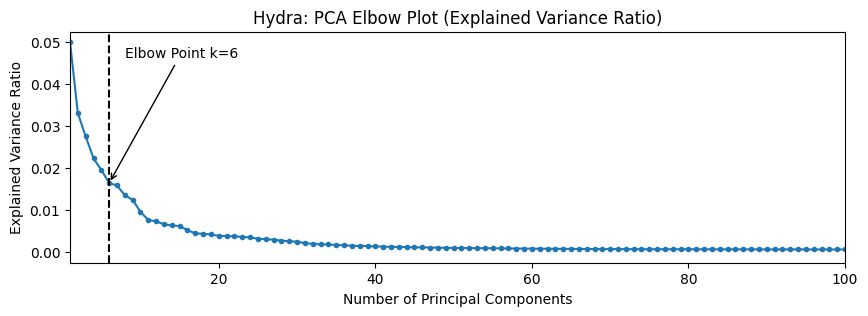

In [103]:
plt.figure(figsize=(10, 3))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', markersize=3)
plt.xlabel("Number of Principal Components")
plt.xlim(1, 100)
plt.ylabel("Explained Variance Ratio")
plt.axvline(x=6, ls='--', c='black')
# annotate the elbow point
plt.annotate('Elbow Point k=6', xy=(6, explained_var[5]), xytext =(8, explained_var[5]+0.03),
             arrowprops=dict(facecolor='black', arrowstyle='->'),)
plt.title("Hydra: PCA Elbow Plot (Explained Variance Ratio)")
plt.show()